# House Prices: CNN

## 1. Loading and preparing the dataset

In [51]:
import os
import time
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import gzip

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

In [52]:
DATA_DIR = "data"
FMNIST_BASE_URL = "http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/"
FMNIST_FILES = {
    "images": "train-images-idx3-ubyte.gz",
    "labels": "train-labels-idx1-ubyte.gz",
}
FMNIST_CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                  'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
N_PER_CLASS = 2000


def _download(fname):
    os.makedirs(DATA_DIR, exist_ok=True)
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        with urllib.request.urlopen(FMNIST_BASE_URL + fname, timeout=20) as r, open(path, 'wb') as f:
            f.write(r.read())
    return path


def load_fashion_mnist():
    img_path = _download(FMNIST_FILES["images"])
    lbl_path = _download(FMNIST_FILES["labels"])
    with gzip.open(img_path, 'rb') as f:
        X = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 28, 28)
    with gzip.open(lbl_path, 'rb') as f:
        y = np.frombuffer(f.read(), np.uint8, offset=8)
    rng = np.random.RandomState(SEED)
    keep = np.concatenate([rng.permutation(np.where(y == c)[0])[:N_PER_CLASS] for c in range(10)])
    keep = rng.permutation(keep)
    return X[keep].astype(np.float32) / 255.0, y[keep].astype(np.int64), FMNIST_CLASSES


loaded = load_fashion_mnist()
DATASET_NAME = "Fashion-MNIST"


X_all, y_all, CLASS_NAMES = loaded
N_CLASSES = len(CLASS_NAMES)

print(f"Dataset: {DATASET_NAME}")
print(f"Images: {len(X_all)}, size of each: {X_all.shape[1]}x{X_all.shape[2]}, classes: {N_CLASSES}")


Dataset: Fashion-MNIST
Images: 20000, size of each: 28x28, classes: 10


## 2. Exploratory data analysis

Shape of image array: (20000, 28, 28)  (N, height, width)
Pixel type: float32, range: [0.00, 1.00]
Pixel mean / std: 0.286 / 0.353
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Class distribution:


,count
T-shirt/top,2000
Trouser,2000
Pullover,2000
Dress,2000
Coat,2000
Sandal,2000
Shirt,2000
Sneaker,2000
Bag,2000
Ankle boot,2000


Ratio of the largest class to the smallest: 1.00


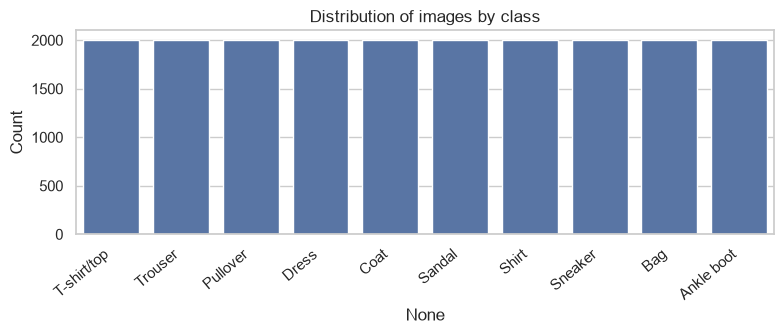

In [53]:
print(f"Shape of image array: {X_all.shape}  (N, height, width)")
print(f"Pixel type: {X_all.dtype}, range: [{X_all.min():.2f}, {X_all.max():.2f}]")
print(f"Pixel mean / std: {X_all.mean():.3f} / {X_all.std():.3f}")
print(f"Classes: {CLASS_NAMES}")

class_counts = pd.Series(y_all).value_counts().sort_index()
class_counts.index = [CLASS_NAMES[i] for i in class_counts.index]
print("\nClass distribution:")
display(class_counts.to_frame('count'))

imbalance = class_counts.max() / class_counts.min()
print(f"Ratio of the largest class to the smallest: {imbalance:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax)
ax.set_title('Distribution of images by class')
ax.set_ylabel('Count')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

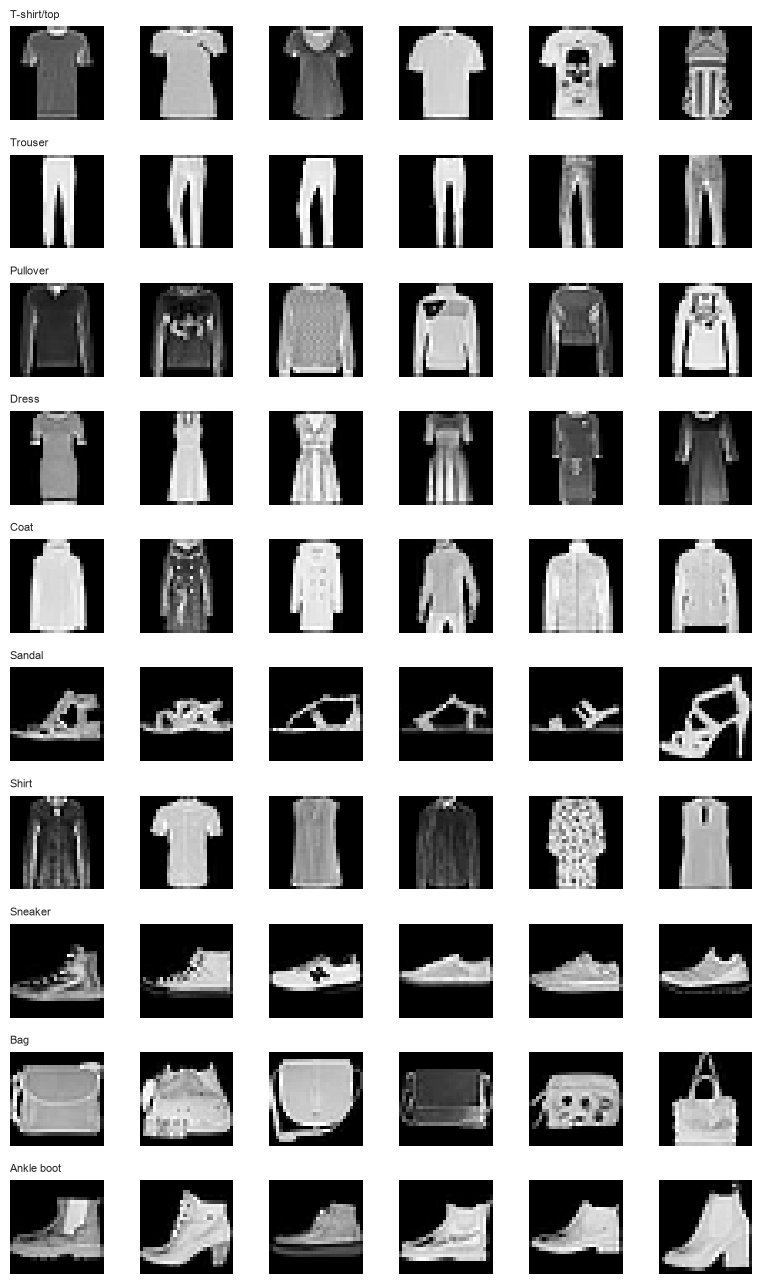

In [54]:
fig, axes = plt.subplots(N_CLASSES, 6, figsize=(8, 1.3 * N_CLASSES))
rng = np.random.RandomState(0)
for c in range(N_CLASSES):
    idx = rng.choice(np.where(y_all == c)[0], 6, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_all[i], cmap='gray')
        axes[c, j].axis('off')
    axes[c, 0].set_title(CLASS_NAMES[c], fontsize=8, loc='left')
plt.tight_layout()
plt.show()

## 3. Preparing data for training

In [55]:
IMG_SIZE = 28

X_t = torch.tensor(X_all).unsqueeze(1)
if X_t.shape[-1] != IMG_SIZE:
    X_t = F.interpolate(X_t, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
y_t = torch.tensor(y_all)

print(f"Image tensor after resizing: {tuple(X_t.shape)}")

Image tensor after resizing: (20000, 1, 28, 28)


### 3.2 Splitting into train, validation, and test sets

In [56]:
idx_all = np.arange(len(y_t))
idx_trainval, idx_test = train_test_split(idx_all, test_size=0.15, random_state=SEED, stratify=y_all)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.15, random_state=SEED, stratify=y_all[idx_trainval])

X_train_raw, y_train = X_t[idx_train], y_t[idx_train]
X_val_raw, y_val = X_t[idx_val], y_t[idx_val]
X_test_raw, y_test = X_t[idx_test], y_t[idx_test]

print(f"train: {len(y_train)} | val: {len(y_val)} | test: {len(y_test)}")
split_share = pd.DataFrame({
    'train': pd.Series(y_train.numpy()).value_counts(normalize=True).sort_index(),
    'val': pd.Series(y_val.numpy()).value_counts(normalize=True).sort_index(),
    'test': pd.Series(y_test.numpy()).value_counts(normalize=True).sort_index(),
})
split_share.index = CLASS_NAMES
display(split_share)

train: 14450 | val: 2550 | test: 3000


,train,val,test
T-shirt/top,0.1,0.1,0.1
Trouser,0.1,0.1,0.1
Pullover,0.1,0.1,0.1
Dress,0.1,0.1,0.1
Coat,0.1,0.1,0.1
Sandal,0.1,0.1,0.1
Shirt,0.1,0.1,0.1
Sneaker,0.1,0.1,0.1
Bag,0.1,0.1,0.1
Ankle boot,0.1,0.1,0.1


### 3.3 Normalization

In [57]:
PIX_MEAN = X_train_raw.mean().item()
PIX_STD = X_train_raw.std().item()
print(f"Normalization parameters (train only): mean={PIX_MEAN:.4f}, std={PIX_STD:.4f}")

def normalize(x):
    return (x - PIX_MEAN) / PIX_STD

X_train, X_val, X_test = normalize(X_train_raw), normalize(X_val_raw), normalize(X_test_raw)
print(f"train: mean={X_train.mean():.3f}, std={X_train.std():.3f} | "
      f"val: mean={X_val.mean():.3f}, std={X_val.std():.3f} | "
      f"test: mean={X_test.mean():.3f}, std={X_test.std():.3f}")

Normalization parameters (train only): mean=0.2860, std=0.3529
train: mean=-0.000, std=1.000 | val: mean=0.007, std=1.003 | test: mean=-0.007, std=0.998


### 3.4 Augmentation

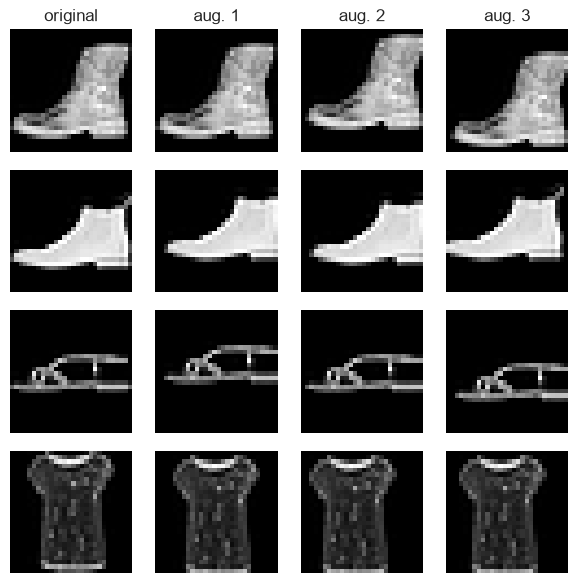

In [58]:
def augment_batch(xb, max_shift=2):
    B, C, H, W = xb.shape
    bg = xb.amin().item()
    padded = F.pad(xb, (max_shift,) * 4, mode='constant', value=bg)
    dx = torch.randint(0, 2 * max_shift + 1, (B,))
    dy = torch.randint(0, 2 * max_shift + 1, (B,))
    return torch.stack([padded[i, :, dy[i]:dy[i] + H, dx[i]:dx[i] + W] for i in range(B)])


sample = X_train[:4]
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for r in range(4):
    axes[r, 0].imshow(sample[r, 0], cmap='gray')
    axes[r, 0].set_title('original' if r == 0 else '')
    for c in range(1, 4):
        axes[r, c].imshow(augment_batch(sample[r:r + 1])[0, 0], cmap='gray')
        if r == 0: 
            axes[r, c].set_title(f'aug. {c}')
for a in axes.ravel(): 
    a.axis('off')
plt.tight_layout()
plt.show()

## 4-5. CNN Architecture

In [59]:
class CNN(nn.Module):
    def __init__(self, in_channels=1, n_classes=10, filters=(16, 32), kernel_size=3,
                 fc_units=64, dropout=0.25, img_size=16):
        super().__init__()
        layers, c = [], in_channels
        for f in filters:
            layers += [nn.Conv2d(c, f, kernel_size, padding=kernel_size // 2),
                       nn.BatchNorm2d(f), nn.ReLU(), nn.MaxPool2d(2)]
            c = f
        self.features = nn.Sequential(*layers)
        self.features.eval()
        with torch.no_grad():
            flat = self.features(torch.zeros(1, in_channels, img_size, img_size)).numel()
        self.features.train()
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(flat, fc_units), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_units, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


demo = CNN(n_classes=N_CLASSES, img_size=IMG_SIZE)
print(demo)
print(f"\nTrainable parameters: {count_params(demo):,}")
print(f"Output shape for a batch of 5 images: {tuple(demo(X_train[:5]).shape)}")

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=1568, out_features=64, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)

Trainable parameters: 105,962
Output shape for a batch of 5 images: (5, 10)


## 6. Configuring the training process

In [60]:
EPOCHS = 20
BATCH_SIZE = 64
LEARNING_RATE = 1e-3


@torch.no_grad()
def predict_logits(model, X, batch=1024):
    model.eval()
    return torch.cat([model(X[i:i + batch]).cpu() for i in range(0, len(X), batch)])


def evaluate_loss_acc(model, X, y):
    logits = predict_logits(model, X)
    return F.cross_entropy(logits, y).item(), (logits.argmax(1) == y).float().mean().item()


def train_model(model, epochs=EPOCHS, lr=LEARNING_RATE, batch_size=BATCH_SIZE,
                augment=False, weight_decay=0.0, seed=SEED, verbose=False):
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_loss, best_state = float('inf'), None

    t0 = time.time()
    for ep in range(epochs):
        model.train()
        tot_loss, tot_correct, n = 0.0, 0, 0
        for xb, yb in loader:
            if augment:
                xb = augment_batch(xb)
            opt.zero_grad()
            out = model(xb)
            loss = F.cross_entropy(out, yb)
            loss.backward()
            opt.step()
            tot_loss += loss.item() * len(yb)
            tot_correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
        v_loss, v_acc = evaluate_loss_acc(model, X_val, y_val)
        hist['train_loss'].append(tot_loss / n)
        hist['train_acc'].append(tot_correct / n)
        hist['val_loss'].append(v_loss)
        hist['val_acc'].append(v_acc)
        if v_loss < best_loss:
            best_loss = v_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (ep % 5 == 0 or ep == epochs - 1):
            print(f"  epoch {ep + 1:>2}/{epochs}: train_loss={hist['train_loss'][-1]:.4f} "
                  f"val_loss={v_loss:.4f} | train_acc={hist['train_acc'][-1]:.3f} val_acc={v_acc:.3f}")
    elapsed = time.time() - t0

    model.load_state_dict(best_state)
    best_epoch = int(np.argmin(hist['val_loss'])) + 1
    info = {'time_s': elapsed, 'best_val_loss': best_loss, 'best_epoch': best_epoch,
            'val_acc_at_best': hist['val_acc'][best_epoch - 1], 'epochs': epochs}
    return model.cpu(), hist, info


## 7. Training the baseline model

In [61]:
torch.manual_seed(SEED)
base_model = CNN(n_classes=N_CLASSES, img_size=IMG_SIZE)
base_model, base_hist, base_info = train_model(base_model, verbose=True)

print(f"\nTraining time: {base_info['time_s']:.1f} s | best epoch: {base_info['best_epoch']} "
      f"| best val_loss: {base_info['best_val_loss']:.4f} "
      f"| val_acc at this epoch: {base_info['val_acc_at_best']:.4f}")

  epoch  1/20: train_loss=0.6565 val_loss=0.4475 | train_acc=0.768 val_acc=0.845
  epoch  6/20: train_loss=0.3034 val_loss=0.3208 | train_acc=0.889 val_acc=0.883
  epoch 11/20: train_loss=0.2460 val_loss=0.3013 | train_acc=0.905 val_acc=0.896
  epoch 16/20: train_loss=0.2063 val_loss=0.2922 | train_acc=0.923 val_acc=0.896
  epoch 20/20: train_loss=0.1914 val_loss=0.2897 | train_acc=0.927 val_acc=0.904

Training time: 77.6 s | best epoch: 20 | best val_loss: 0.2897 | val_acc at this epoch: 0.9039


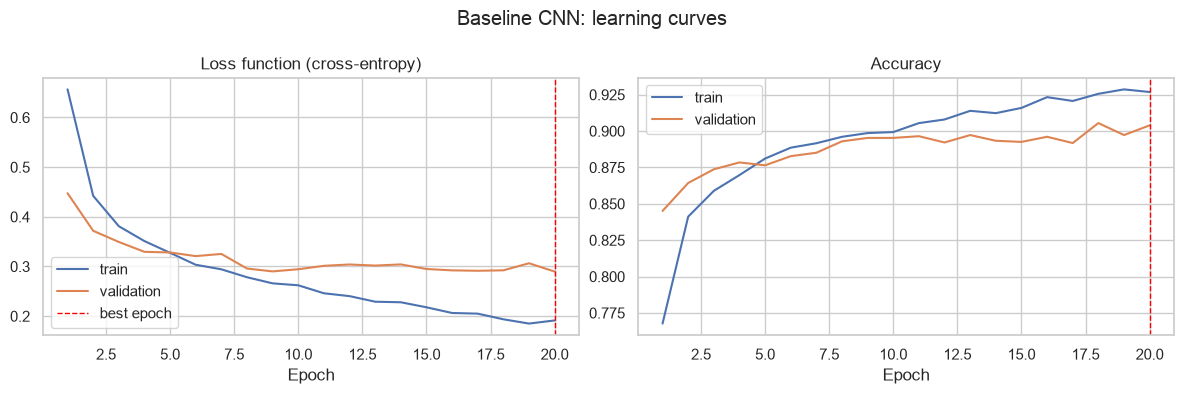

In [62]:
def plot_history(hist, title, best_epoch=None):
    ep = np.arange(1, len(hist['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(ep, hist['train_loss'], label='train')
    axes[0].plot(ep, hist['val_loss'], label='validation')
    axes[0].set_title('Loss function (cross-entropy)')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[1].plot(ep, hist['train_acc'], label='train')
    axes[1].plot(ep, hist['val_acc'], label='validation')
    axes[1].set_title('Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    if best_epoch:
        for a in axes: a.axvline(best_epoch, color='red', ls='--', lw=1, label='best epoch')
        axes[0].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(base_hist, 'Baseline CNN: learning curves', base_info['best_epoch'])

In [63]:
gap_loss = base_hist['val_loss'][-1] - base_hist['train_loss'][-1]
gap_acc = base_hist['train_acc'][-1] - base_hist['val_acc'][-1]
print(f"Last epoch: train_loss={base_hist['train_loss'][-1]:.4f}, val_loss={base_hist['val_loss'][-1]:.4f} "
      f"(difference {gap_loss:+.4f})")
print(f"Last epoch: train_acc={base_hist['train_acc'][-1]:.4f}, val_acc={base_hist['val_acc'][-1]:.4f} "
      f"(difference {gap_acc:+.4f})")
print(f"Minimum val_loss reached at epoch {base_info['best_epoch']} of {EPOCHS}.")

Last epoch: train_loss=0.1914, val_loss=0.2897 (difference +0.0984)
Last epoch: train_acc=0.9269, val_acc=0.9039 (difference +0.0229)
Minimum val_loss reached at epoch 20 of 20.


## 8. Varying architecture and training parameters

In [64]:
experiments = {
    'Baseline':          dict(model=dict(), train=dict()),
    'lr = 1e-2':         dict(model=dict(), train=dict(lr=1e-2)),
    'lr = 1e-4':         dict(model=dict(), train=dict(lr=1e-4)),
    'dropout = 0.5':     dict(model=dict(dropout=0.5), train=dict()),
    'dropout = 0.0':     dict(model=dict(dropout=0.0), train=dict()),
    'filters 32-64':     dict(model=dict(filters=(32, 64)), train=dict()),
    '1 conv block':      dict(model=dict(filters=(16,)), train=dict()),
    'batch size = 16':   dict(model=dict(), train=dict(batch_size=16)),
    'augmentation':      dict(model=dict(), train=dict(augment=True)),
}

results, trained = {}, {}
for name, cfg in experiments.items():
    if name == 'Baseline':
        m, h, info = base_model, base_hist, base_info
    else:
        torch.manual_seed(SEED)
        m = CNN(n_classes=N_CLASSES, img_size=IMG_SIZE, **cfg['model'])
        m, h, info = train_model(m, **cfg['train'])
    trained[name] = (m, h, info)
    print(f"{name:<20} | parameters: {count_params(m):>7,} | best epoch: {info['best_epoch']:>2} "
          f"| val_loss: {info['best_val_loss']:.4f} | val_acc: {info['val_acc_at_best']:.4f} "
          f"| {info['time_s']:.0f} s")

Baseline             | parameters: 105,962 | best epoch: 20 | val_loss: 0.2897 | val_acc: 0.9039 | 78 s
lr = 1e-2            | parameters: 105,962 | best epoch: 18 | val_loss: 0.3176 | val_acc: 0.8851 | 73 s
lr = 1e-4            | parameters: 105,962 | best epoch: 18 | val_loss: 0.3023 | val_acc: 0.8890 | 68 s
dropout = 0.5        | parameters: 105,962 | best epoch: 20 | val_loss: 0.2954 | val_acc: 0.8871 | 69 s
dropout = 0.0        | parameters: 105,962 | best epoch:  5 | val_loss: 0.3003 | val_acc: 0.8906 | 62 s
filters 32-64        | parameters: 220,426 | best epoch:  7 | val_loss: 0.2817 | val_acc: 0.8961 | 120 s
1 conv block         | parameters: 201,610 | best epoch: 13 | val_loss: 0.3145 | val_acc: 0.8922 | 57 s
batch size = 16      | parameters: 105,962 | best epoch:  9 | val_loss: 0.3007 | val_acc: 0.8929 | 141 s
augmentation         | parameters: 105,962 | best epoch: 20 | val_loss: 0.2873 | val_acc: 0.8941 | 73 s


## 9. Comparison of the baseline and modified models

In [65]:
rows = []
for name, (m, h, info) in trained.items():
    b = info['best_epoch'] - 1
    logits = predict_logits(m, X_val)
    pred = logits.argmax(1).numpy()
    _, _, f1, _ = precision_recall_fscore_support(y_val.numpy(), pred, average='macro', zero_division=0)
    rows.append({
        'Configuration': name,
        'Parameters': count_params(m),
        'Best epoch': info['best_epoch'],
        'val_loss (best)': round(info['best_val_loss'], 4),
        'train_acc': round(h['train_acc'][b], 4),
        'val_acc': round(h['val_acc'][b], 4),
        'val macro-F1': round(f1, 4),
        'train-val acc gap': round(h['train_acc'][b] - h['val_acc'][b], 4),
        'Time, s': round(info['time_s'], 1),
    })
    
cmp_df = pd.DataFrame(rows).set_index('Configuration')
display(cmp_df.sort_values('val_acc', ascending=False))

,Parameters,Best epoch,val_loss (best),train_acc,val_acc,val macro-F1,train-val acc gap,"Time, s"
Configuration,,,,,,,,
Baseline,105962,20,0.2897,0.9269,0.9039,0.9028,0.0229,77.6
filters 32-64,220426,7,0.2817,0.9014,0.8961,0.8948,0.0053,120.5
augmentation,105962,20,0.2873,0.8755,0.8941,0.8931,-0.0186,73.3
batch size = 16,105962,9,0.3007,0.9011,0.8929,0.8929,0.0082,141.4
1 conv block,201610,13,0.3145,0.9183,0.8922,0.8908,0.0261,56.8
dropout = 0.0,105962,5,0.3003,0.9127,0.8906,0.8893,0.0221,62.3
lr = 1e-4,105962,18,0.3023,0.8937,0.8890,0.8883,0.0047,67.9
dropout = 0.5,105962,20,0.2954,0.8736,0.8871,0.8850,-0.0134,69.4
lr = 1e-2,105962,18,0.3176,0.8872,0.8851,0.8869,0.0021,73.0


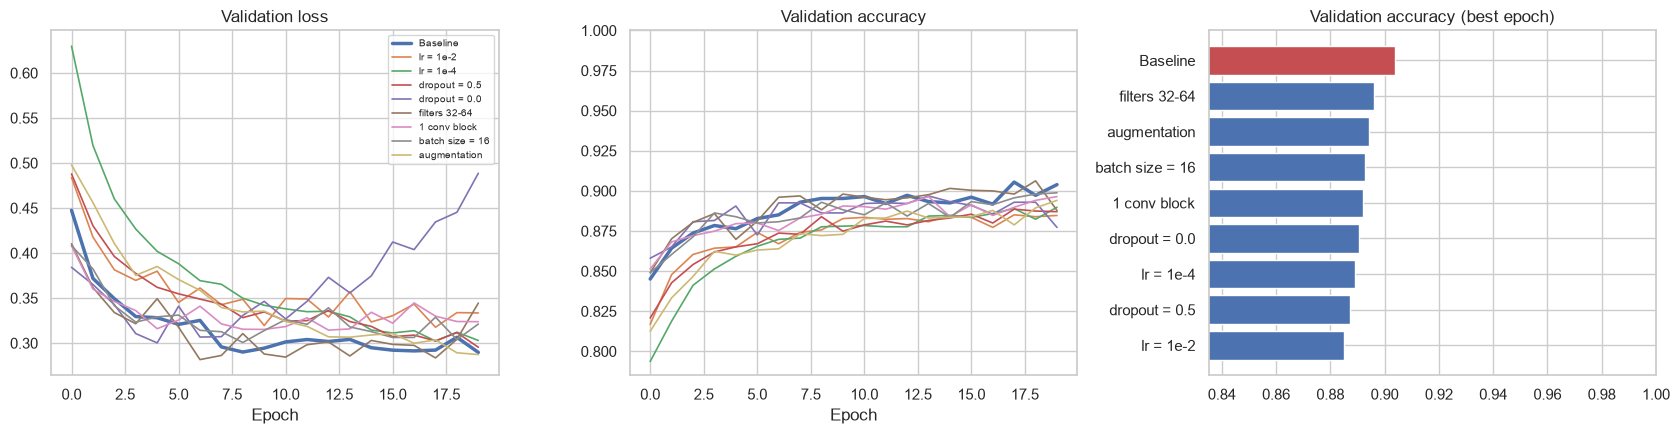

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name, (m, h, info) in trained.items():
    lw = 2.5 if name == 'Baseline' else 1.2
    axes[0].plot(h['val_loss'], label=name, lw=lw)
    axes[1].plot(h['val_acc'], label=name, lw=lw)
axes[0].set_title('Validation loss')
axes[0].set_xlabel('Epoch')
axes[0].legend(fontsize=7)
axes[1].set_title('Validation accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylim(max(0.0, cmp_df['val_acc'].min() - 0.1), 1.0)

order = cmp_df.sort_values('val_acc').index
axes[2].barh(order, cmp_df.loc[order, 'val_acc'], color=['#C44E52' if n == 'Baseline' else '#4C72B0' for n in order])
axes[2].set_xlim(max(0.0, cmp_df['val_acc'].min() - 0.05), 1.0)
axes[2].set_title('Validation accuracy (best epoch)')
plt.tight_layout()
plt.show()

### Real effect vs randomness

In [67]:
seed_accs = [base_info['val_acc_at_best']]
for s in (SEED + 1, SEED + 2):
    torch.manual_seed(s)
    m = CNN(n_classes=N_CLASSES, img_size=IMG_SIZE)
    _, _, info_s = train_model(m, seed=s)
    seed_accs.append(info_s['val_acc_at_best'])
SEED_STD = float(np.std(seed_accs, ddof=1))
print(f"val_acc of the baseline model for 3 seeds: {[round(a, 4) for a in seed_accs]}")
print(f"Mean = {np.mean(seed_accs):.4f}, standard deviation = {SEED_STD:.4f}")

STEP = 1 / len(y_val)
SIG_THRESHOLD = max(2 * SEED_STD, 2 * STEP)
print(f"\nValidation sample size: {len(y_val)}, one image = {STEP:.2%} of accuracy.")
print(f"Threshold of a 'noticeable' difference = max(2 x std between seeds, 2 images) = {SIG_THRESHOLD:.2%}")

val_acc of the baseline model for 3 seeds: [0.9039, 0.9035, 0.8965]
Mean = 0.9013, standard deviation = 0.0042

Validation sample size: 2550, one image = 0.04% of accuracy.
Threshold of a 'noticeable' difference = max(2 x std between seeds, 2 images) = 0.84%


In [68]:
base_acc = cmp_df.loc['Baseline', 'val_acc']
delta = (cmp_df['val_acc'] - base_acc).drop('Baseline')
verdicts = pd.DataFrame({
    'delta val_acc relative to baseline': delta.round(4),
    'noticeable difference?': ['yes' if abs(d) >= SIG_THRESHOLD else 'no (within noise)' for d in delta],
    'delta time, s': (cmp_df['Time, s'] - cmp_df.loc['Baseline', 'Time, s']).drop('Baseline').round(1),
    'delta params': (cmp_df['Parameters'] - cmp_df.loc['Baseline', 'Parameters']).drop('Baseline'),
})
display(verdicts.sort_values('delta val_acc relative to baseline', ascending=False))

,delta val_acc relative to baseline,noticeable difference?,"delta time, s",delta params
Configuration,,,,
filters 32-64,-0.0078,no (within noise),42.9,114464
augmentation,-0.0098,yes,-4.3,0
batch size = 16,-0.0110,yes,63.8,0
1 conv block,-0.0117,yes,-20.8,95648
dropout = 0.0,-0.0133,yes,-15.3,0
lr = 1e-4,-0.0149,yes,-9.7,0
dropout = 0.5,-0.0168,yes,-8.2,0
lr = 1e-2,-0.0188,yes,-4.6,0


## 10. Evaluating the best model on the test set

In [69]:
best_name = cmp_df.sort_values(['val_acc', 'val_loss (best)'], ascending=[False, True]).index[0]
best_model, best_hist, best_info = trained[best_name]
print(f"Best configuration by validation: {best_name}")
print(f"  val_acc = {cmp_df.loc[best_name, 'val_acc']:.4f}, "
      f"val_loss = {cmp_df.loc[best_name, 'val_loss (best)']:.4f}, "
      f"parameters: {cmp_df.loc[best_name, 'Parameters']:,}")

test_logits = predict_logits(best_model, X_test)
test_proba = F.softmax(test_logits, dim=1).numpy()
y_pred = test_logits.argmax(1).numpy()
y_true = y_test.numpy()

acc = accuracy_score(y_true, y_pred)
P_macro, R_macro, F1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
P_w, R_w, F1_w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)

overall = pd.DataFrame({'Accuracy': [acc], 'Precision': [P_macro], 'Recall': [R_macro], 'F1-score': [F1_macro]},
                       index=['macro average']).round(4)
overall.loc['weighted average'] = [acc, P_w, R_w, F1_w]
overall = overall.round(4)
print("\nOverall metrics on the test set:")
display(overall)

p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(N_CLASSES), zero_division=0)
per_class = pd.DataFrame({'Precision': p, 'Recall': r, 'F1-score': f, 'Count in test': s},
                         index=CLASS_NAMES).round(4)
print("Per-class metrics:")
display(per_class)

Best configuration by validation: Baseline
  val_acc = 0.9039, val_loss = 0.2897, parameters: 105,962

Overall metrics on the test set:


,Accuracy,Precision,Recall,F1-score
macro average,0.903,0.9027,0.903,0.9023
weighted average,0.903,0.9027,0.903,0.9023


Per-class metrics:


,Precision,Recall,F1-score,Count in test
T-shirt/top,0.8254,0.8667,0.8455,300
Trouser,0.9866,0.9833,0.9850,300
Pullover,0.8776,0.8600,0.8687,300
Dress,0.8825,0.9267,0.9041,300
Coat,0.8204,0.8833,0.8507,300
Sandal,0.9637,0.9733,0.9685,300
Shirt,0.7786,0.6800,0.7260,300
Sneaker,0.9500,0.9500,0.9500,300
Bag,0.9863,0.9567,0.9712,300
Ankle boot,0.9564,0.9500,0.9532,300


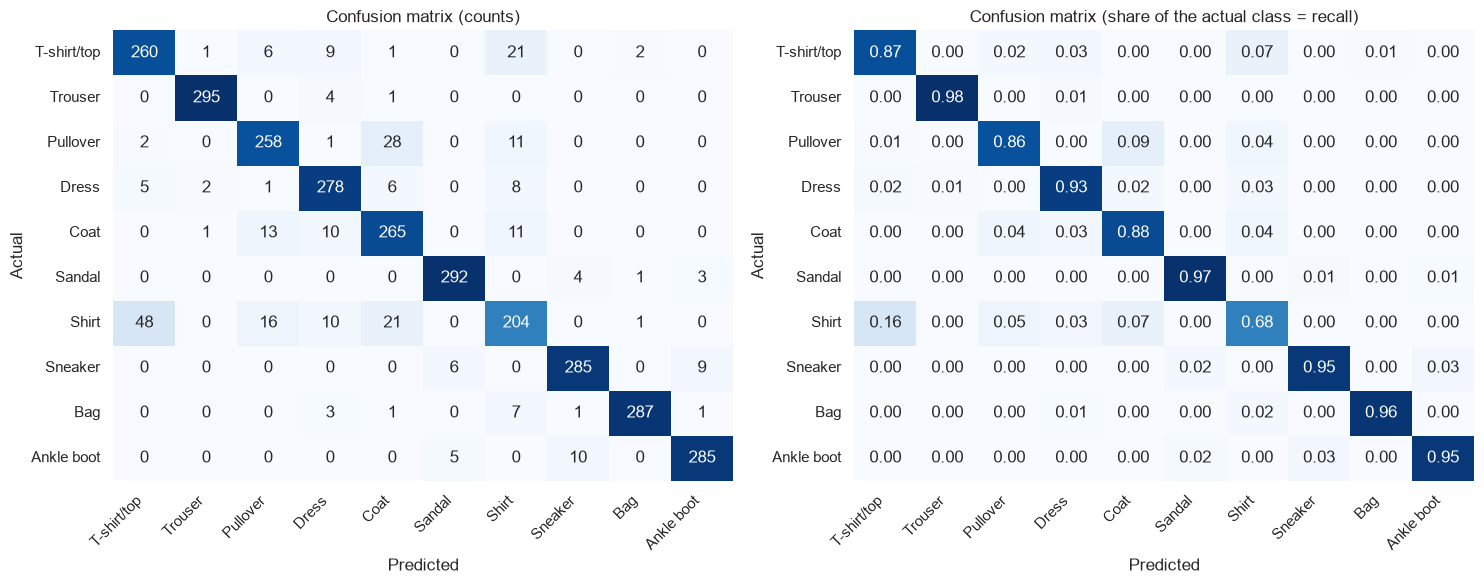

Most frequent errors (actual -> predicted):
  Shirt -> T-shirt/top: 48
  Pullover -> Coat: 28
  T-shirt/top -> Shirt: 21
  Shirt -> Coat: 21
  Shirt -> Pullover: 16
  Coat -> Pullover: 13


In [70]:
cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[0], cbar=False)
axes[0].set_title('Confusion matrix (counts)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[1], cbar=False)
axes[1].set_title('Confusion matrix (share of the actual class = recall)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
for a in axes: 
    plt.setp(a.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.show()

off = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(N_CLASSES) for j in range(N_CLASSES)
       if i != j and cm[i, j] > 0]
off = sorted(off, key=lambda t: -t[2])[:6]
print("Most frequent errors (actual -> predicted):")
for a, b, n in off:
    print(f"  {a} -> {b}: {n}")

## 11. Visualization of results

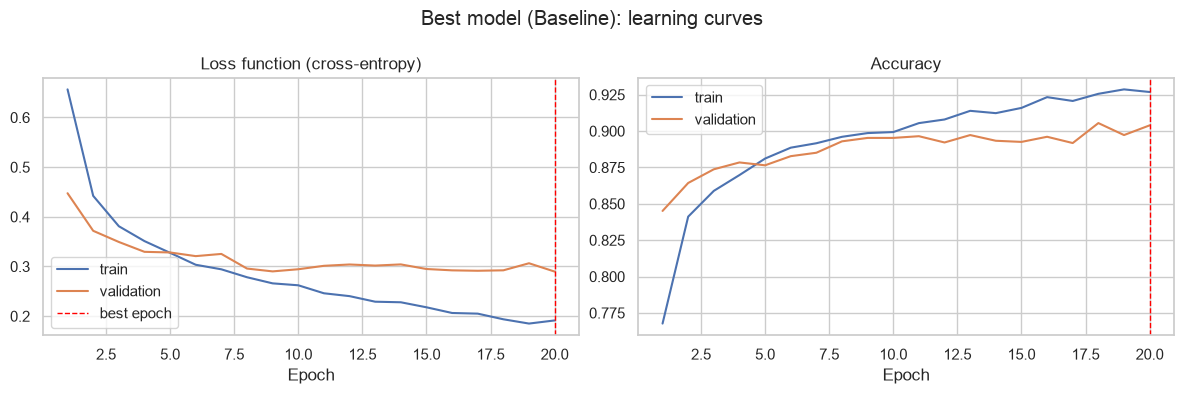

In [71]:
plot_history(best_hist, f'Best model ({best_name}): learning curves', best_info['best_epoch'])

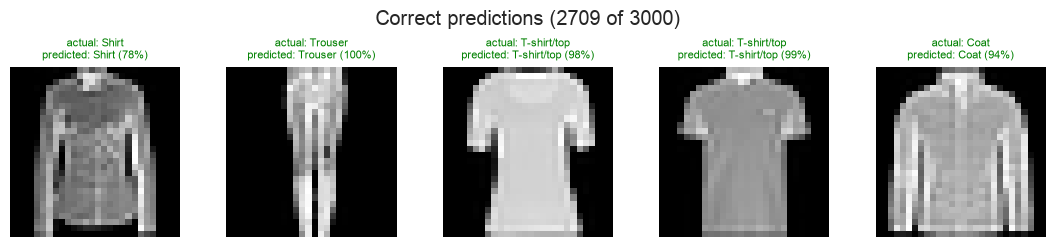

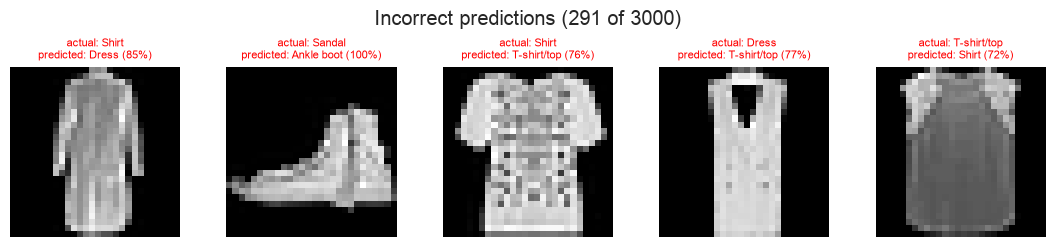

In [72]:
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx = np.where(y_pred != y_true)[0]
rng = np.random.RandomState(1)
conf = test_proba.max(1)

def show_examples(indices, title, n=5):
    if len(indices) == 0:
        print(f"{title}: no examples.")
        return
    pick = rng.choice(indices, min(n, len(indices)), replace=False)
    cols = 5
    rows = int(np.ceil(len(pick) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for a in axes: a.axis('off')
    for a, i in zip(axes, pick):
        a.imshow(X_test_raw[i, 0], cmap='gray')
        ok = y_pred[i] == y_true[i]
        a.set_title(f"actual: {CLASS_NAMES[y_true[i]]}\npredicted: {CLASS_NAMES[y_pred[i]]} ({conf[i]:.0%})",
                    fontsize=8, color='green' if ok else 'red')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_examples(correct_idx, f'Correct predictions ({len(correct_idx)} of {len(y_true)})')
show_examples(wrong_idx, f'Incorrect predictions ({len(wrong_idx)} of {len(y_true)})')

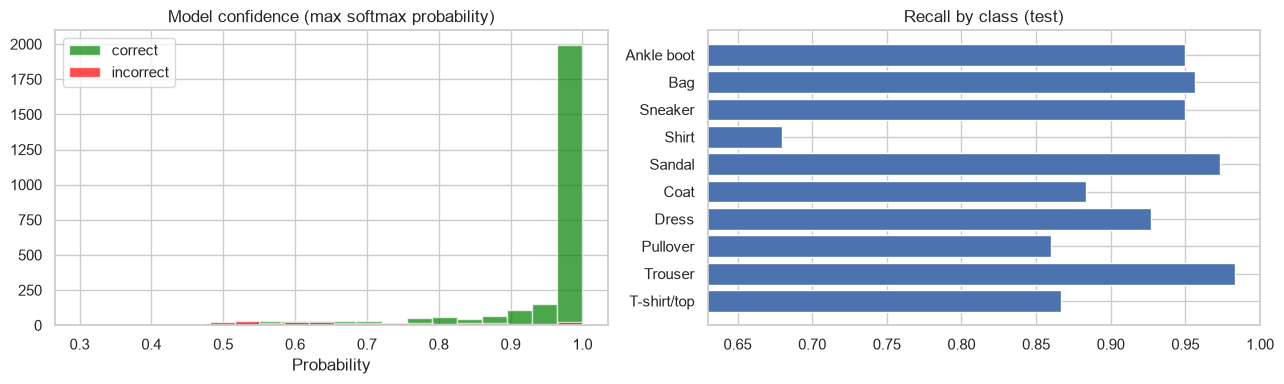

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(conf[correct_idx], bins=20, alpha=0.7, label='correct', color='green')
if len(wrong_idx):
    axes[0].hist(conf[wrong_idx], bins=20, alpha=0.7, label='incorrect', color='red')
axes[0].set_title('Model confidence (max softmax probability)')
axes[0].set_xlabel('Probability')
axes[0].legend()

axes[1].barh(CLASS_NAMES, per_class['Recall'])
axes[1].set_xlim(max(0.0, per_class['Recall'].min() - 0.05), 1.0)
axes[1].set_title('Recall by class (test)')
plt.tight_layout()
plt.show()